It: 0, Loss: 4.331e+00, Loss_ics: 2.905e-01, Loss_bcs: 2.826e+00, Loss_res: 1.214e+00, Time: 1.93
It: 1000, Loss: 5.299e-04, Loss_ics: 1.249e-05, Loss_bcs: 3.144e-04, Loss_res: 2.030e-04, Time: 4.08
It: 2000, Loss: 8.110e-04, Loss_ics: 1.196e-04, Loss_bcs: 6.158e-04, Loss_res: 7.560e-05, Time: 4.08
It: 3000, Loss: 6.680e-05, Loss_ics: 6.744e-07, Loss_bcs: 3.746e-05, Loss_res: 2.866e-05, Time: 4.32
It: 4000, Loss: 2.229e-04, Loss_ics: 2.767e-05, Loss_bcs: 1.090e-04, Loss_res: 8.621e-05, Time: 4.25
It: 5000, Loss: 1.683e-04, Loss_ics: 3.918e-05, Loss_bcs: 4.397e-05, Loss_res: 8.520e-05, Time: 4.26
It: 6000, Loss: 9.024e-04, Loss_ics: 3.626e-05, Loss_bcs: 2.172e-04, Loss_res: 6.489e-04, Time: 4.27
It: 7000, Loss: 7.416e-05, Loss_ics: 6.615e-07, Loss_bcs: 2.443e-05, Loss_res: 4.907e-05, Time: 4.28
It: 8000, Loss: 6.727e-05, Loss_ics: 7.389e-06, Loss_bcs: 2.790e-05, Loss_res: 3.198e-05, Time: 4.31
It: 9000, Loss: 1.408e-04, Loss_ics: 3.016e-06, Loss_bcs: 9.754e-05, Loss_res: 4.026e-05, Time

C:\Users\swj02\AppData\Local\Temp\ipykernel_17396\1866016487.py:328: MatplotlibDeprecationWarning: Getting the array from a PolyQuadMesh will return the full array in the future (uncompressed). To get this behavior now set the PolyQuadMesh with a 2D array .set_array(data2d).
  plt.colorbar()
C:\Users\swj02\AppData\Local\Temp\ipykernel_17396\1866016487.py:335: MatplotlibDeprecationWarning: Getting the array from a PolyQuadMesh will return the full array in the future (uncompressed). To get this behavior now set the PolyQuadMesh with a 2D array .set_array(data2d).
  plt.colorbar()
C:\Users\swj02\AppData\Local\Temp\ipykernel_17396\1866016487.py:342: MatplotlibDeprecationWarning: Getting the array from a PolyQuadMesh will return the full array in the future (uncompressed). To get this behavior now set the PolyQuadMesh with a 2D array .set_array(data2d).
  plt.colorbar(format='%.0e')


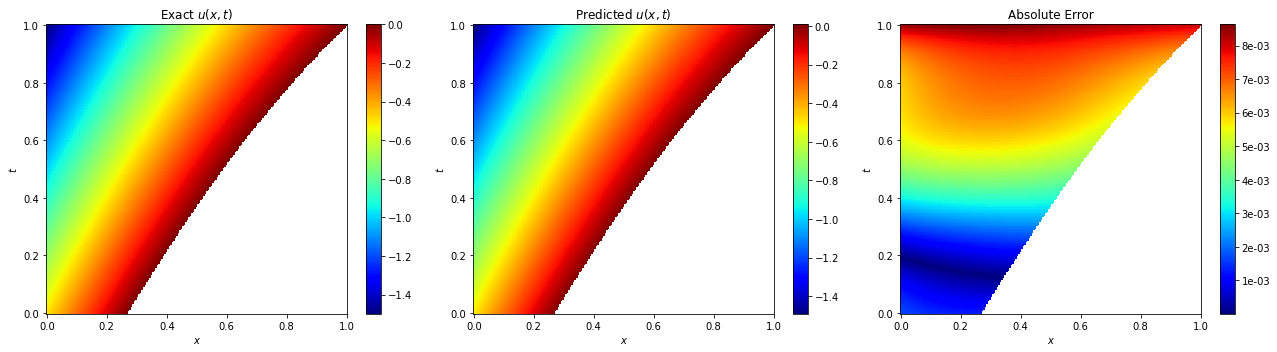

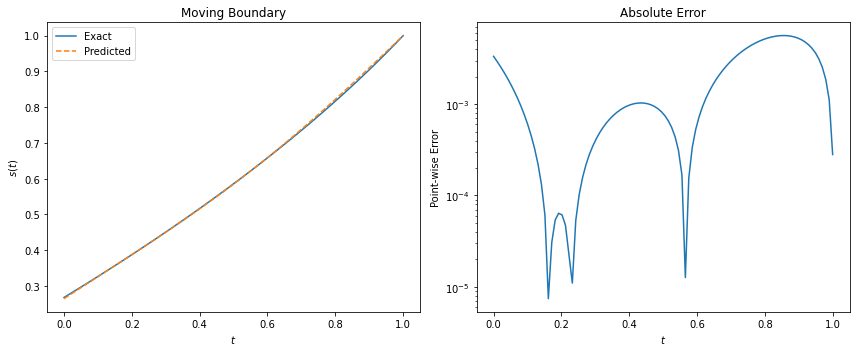

In [7]:
import tensorflow as tf
import numpy as np
import timeit
import matplotlib.pyplot as plt
from scipy.interpolate import griddata
import os

# Define the Sampler class
class Sampler:
    def __init__(self, dim, coords, func, name=None):
        self.dim = dim
        self.coords = coords.astype(np.float32)  # Ensure float32
        self.func = func
        self.name = name

    def sample(self, N):
        x = self.coords[0:1, :] + (self.coords[1:2, :] - self.coords[0:1, :]) * np.random.uniform(0, 1, size=(N, self.dim)).astype(np.float32)  # Ensure float32
        y = self.func(x).astype(np.float32)  # Ensure float32
        return x, y

# Define the Stefan1D_direct class
class Stefan1D_direct:
    def __init__(self, layers_u, layers_s, ics_sampler, Ncs_sampler, res_sampler):
        # Normalization constants
        X, _ = res_sampler.sample(np.int32(1e5))
        self.mu_X, self.sigma_X = X.mean(0).astype(np.float32), X.std(0).astype(np.float32)  # Ensure float32
        self.mu_x, self.sigma_x = self.mu_X[0], self.sigma_X[0]
        self.mu_t, self.sigma_t = self.mu_X[1], self.sigma_X[1]

        # Samplers
        self.ics_sampler = ics_sampler
        self.Ncs_sampler = Ncs_sampler
        self.res_sampler = res_sampler

        # Initialize network weights and biases
        self.layers_u = layers_u
        self.weights_u, self.biases_u = self.initialize_NN(layers_u)
        
        self.layers_s = layers_s
        self.weights_s, self.biases_s = self.initialize_NN(layers_s)

        # Optimizer
        # Learning rate schedule
        initial_learning_rate = 1e-3
        decay_steps = 1000
        decay_rate = 0.9
        learning_rate_schedule = tf.keras.optimizers.schedules.ExponentialDecay(
            initial_learning_rate=initial_learning_rate,
            decay_steps=decay_steps,
            decay_rate=decay_rate,
            staircase=True
        )

        # Optimizer with decaying learning rate
        self.optimizer = tf.keras.optimizers.Adam(learning_rate=learning_rate_schedule)

    # Xavier initialization
    def xavier_init(self, size):
        in_dim = size[0]
        out_dim = size[1]
        xavier_stddev = 1. / np.sqrt((in_dim + out_dim) / 2.)
        return tf.Variable(tf.random.normal([in_dim, out_dim], dtype=tf.float32) * xavier_stddev)  # Ensure float32

    # Initialize network weights and biases using Xavier initialization
    def initialize_NN(self, layers):
        weights = []
        biases = []
        num_layers = len(layers)
        for l in range(0, num_layers - 1):
            W = self.xavier_init(size=[layers[l], layers[l + 1]])
            b = tf.Variable(tf.zeros([1, layers[l + 1]], dtype=tf.float32))  # Ensure float32
            weights.append(W)
            biases.append(b)
        return weights, biases

    # Forward pass for network u
    @tf.function
    def forward_pass_u(self, H):
        num_layers = len(self.layers_u)
        for l in range(0, num_layers - 2):
            W = self.weights_u[l]
            b = self.biases_u[l]
            H = tf.tanh(tf.add(tf.matmul(H, W), b))
        W = self.weights_u[-1]
        b = self.biases_u[-1]
        H = tf.add(tf.matmul(H, W), b)
        return H

    # Forward pass for network s
    @tf.function
    def forward_pass_s(self, H):
        num_layers = len(self.layers_s)
        for l in range(0, num_layers - 2):
            W = self.weights_s[l]
            b = self.biases_s[l]
            H = tf.tanh(tf.add(tf.matmul(H, W), b))
        W = self.weights_s[-1]
        b = self.biases_s[-1]
        H = tf.add(tf.matmul(H, W), b)
        return H

    # Network for u
    @tf.function
    def net_u(self, x, t):
        u = self.forward_pass_u(tf.concat([x, t], 1))
        return u

    # Network for s
    @tf.function
    def net_s(self, t):
        s = self.forward_pass_s(t)
        return s

    @tf.function
    def net_u_x(self, x, t):
        u = self.net_u(x, t)
        u_x = tf.gradients(u, x)[0] / self.sigma_x
        return u_x

    # Forward pass for residual
    @tf.function
    def net_r_u(self, x, t):
        u = self.net_u(x, t)
        u_t = tf.gradients(u, t)[0] / self.sigma_t
        u_x = tf.gradients(u, x)[0] / self.sigma_x
        u_xx = tf.gradients(u_x, x)[0] / self.sigma_x
        residual = u_t - u_xx
        return residual

    @tf.function
    def net_r_Nc(self, t):
        s = self.net_s(t)

        # Normalize s
        s = (s - self.mu_x) / self.sigma_x

        u_x = self.net_u_x(s, t)
        residual = u_x
        return residual

    # Function to fetch mini-batches
    def fetch_minibatch(self, sampler, N):
        X, Y = sampler.sample(N)
        X = (X - self.mu_X) / self.sigma_X
        return X, Y

    # Training function using GradientTape
    @tf.function
    def train_step(self, X_ics_batch, u_ics_batch, X_Ncs_batch, u_Ncs_batch, X_res_batch):
        
        # tf_dict = {self.x_u_tf: X_res_batch[:, 0:1], self.t_u_tf: X_res_batch[:, 1:2],
        # self.x_0_tf: X_ics_batch[:, 0:1], self.t_0_tf: X_ics_batch[:, 1:2],
        # self.u_0_tf: u_ics_batch,
        # self.x_Nc_tf: X_Ncs_batch[:, 0:1], self.t_Nc_tf: X_Ncs_batch[:, 1:2],
        # self.s_Nc_tf: u_Ncs_batch,
        # self.x_r_tf: X_res_batch[:, 0:1], self.t_r_tf: X_res_batch[:, 1:2]}
        
        
        X_u_tf = X_res_batch[:, 0:1]
        T_u_tf = X_res_batch[:, 1:2]

        with tf.GradientTape() as tape:
            # Loss calculation
            s_pred = self.net_s(T_u_tf)
            u_pred = self.net_u(X_u_tf, T_u_tf)
            
            u_0_pred = self.net_u(X_ics_batch[:, 0:1], X_ics_batch[:, 1:2])
            u_Sbc_pred = self.net_u((s_pred - self.mu_x) / self.sigma_x, T_u_tf)
            s_0_pred = self.net_s(X_ics_batch[:, 1:2])
            u_Nc_pred = self.net_u_x(X_Ncs_batch[:, 0:1], X_Ncs_batch[:, 1:2])
            r_u_pred = self.net_r_u(X_res_batch[:, 0:1], X_res_batch[:, 1:2])
            r_Nc_pred = self.net_r_Nc(X_Ncs_batch[:, 1:2])

            # Losses
            loss_u_0 = tf.reduce_mean(tf.square(u_0_pred - u_ics_batch))
            loss_Sbc = tf.reduce_mean(tf.square(u_Sbc_pred))
            loss_s_0 = tf.reduce_mean(tf.square(s_0_pred - (2.0 - np.sqrt(3))))
            loss_uNc = tf.reduce_mean(tf.square(u_Nc_pred - 2.0))

            loss_res = tf.reduce_mean(tf.square(r_u_pred))
            loss_SNc = tf.reduce_mean(tf.square(r_Nc_pred - u_Ncs_batch))

            # Total loss
            loss_ics = loss_s_0 + loss_u_0
            loss_bcs = loss_Sbc + loss_SNc + loss_uNc
            loss = loss_bcs + loss_ics + loss_res

            #I have a doubt in this part
        # Compute gradients and apply optimizer
        gradients = tape.gradient(loss, self.weights_u + self.biases_u + self.weights_s + self.biases_s)
        self.optimizer.apply_gradients(zip(gradients, self.weights_u + self.biases_u + self.weights_s + self.biases_s))
        return loss, loss_ics, loss_bcs, loss_res

    # Main training loop
    def train(self, nIter=10000, batch_size=128):
        start_time = timeit.default_timer()
        for it in range(nIter):
            # Fetch boundary and Neumann mini-batches
            X_ics_batch, u_ics_batch = self.fetch_minibatch(self.ics_sampler, batch_size)
            X_Ncs_batch, u_Ncs_batch = self.fetch_minibatch(self.Ncs_sampler, batch_size)
   
            # Fetch residual mini-batch
            X_res_batch, _ = self.fetch_minibatch(self.res_sampler, batch_size)

            # Perform a single training step
            loss, loss_ics, loss_bcs, loss_res = self.train_step(X_ics_batch, u_ics_batch, X_Ncs_batch, u_Ncs_batch, X_res_batch)

            # Print loss periodically
            if it % 1000 == 0:
                elapsed = timeit.default_timer() - start_time
                print(f'It: {it}, Loss: {loss:.3e}, Loss_ics: {loss_ics:.3e}, Loss_bcs: {loss_bcs:.3e}, Loss_res: {loss_res:.3e}, Time: {elapsed:.2f}')
                start_time = timeit.default_timer()

    # Predictions for u
    @tf.function
    def predict_u(self, X_star):
        X_star = (X_star - self.mu_X) / self.sigma_X
        return self.net_u(X_star[:, 0:1], X_star[:, 1:2])

    # Predictions for s
    @tf.function
    def predict_s(self, X_star):
        X_star = (X_star - self.mu_X) / self.sigma_X
        return self.net_s(X_star[:, 1:2])
    
# Main execution
if __name__ == '__main__':

    # Exact Solution
    def u(z):
        # x = (x, t)
        x = z[:, 0: 1]
        t = z[:, 1: 2]
        u = - 0.5 * x**2  + 2 * x - t - 0.5
        return u

    # Exact free boundary
    def s(x):
        t = x[:, 1: 2]
        s = 2 - np.sqrt(3 - 2 * t)
        return s

    def h(x):
        # du / dx (s(t), t) = h(t)   Stefan Neumann Condition
        t = x[:, 1: 2]
        h = np.sqrt(3 - 2 * t)
        return h

    def g(x):
        # - du /dx (0, t) = g(t)  Neumann Condition
        N = x.shape[0]
        return 2.0 * np.ones((N,1))

    def u_0(x):
        #  Initial Condition
        x = x[:, 0: 1]
        return - 0.5 * x**2 + 2 * x - 0.5

    def S_0(x):
        # Initial Condtion for S0
        S_0 = 2 - np.sqrt(3)
        N = x.shape[0]
        return S_0 * np.ones((N, 1))

    # Domain boundaries
    ic_coords = np.array([[0.0, 0.0],
                          [1.0, 0.0]], dtype=np.float32)  # Ensure float32
    Nc_coords = np.array([[0.0, 0.0],
                          [0.0, 1.0]], dtype=np.float32)  # Ensure float32
    dom_coords = np.array([[0.0, 0.0],
                           [1.0, 1.0]], dtype=np.float32)  # Ensure float32

    # Create boundary conditions samplers
    ics_sampler = Sampler(2, ic_coords, lambda x: u_0(x), name='Initial Condition')
    Ncs_sampler = Sampler(2, Nc_coords, lambda x: h(x), name='Stefan Neumann Boundary Condition') 

    # Create residual sampler
    res_sampler = Sampler(2, dom_coords, lambda x: u(x), name='Forcing')

    # Define model
    layers_u = [2, 100, 100, 100, 1]
    layers_s = [1, 100, 100, 100, 1]  
    model = Stefan1D_direct(layers_u, layers_s, ics_sampler, Ncs_sampler, res_sampler)

    # Train model
    model.train(nIter=10000, batch_size=128)

    # Test data
    nn = 200
    x = np.linspace(dom_coords[0, 0], dom_coords[1, 0], nn).astype(np.float32)[:, None]  # Ensure float32
    t = np.linspace(dom_coords[0, 1], dom_coords[1, 1], nn).astype(np.float32)[:, None]  # Ensure float32
    X, T = np.meshgrid(x, t)
    X_star = np.hstack((X.flatten()[:, None], T.flatten()[:, None]))
        
    # Exact solutions
    u_star = u(X_star)
    s_star = s(X_star)
    
    # Predictions
    u_pred = model.predict_u(X_star).numpy()  # Convert to NumPy array
    s_pred = model.predict_s(X_star).numpy()  # Convert to NumPy array

    # Errors
    error_u = np.linalg.norm(u_star - u_pred, 2) / np.linalg.norm(u_star, 2)
    error_s = np.linalg.norm(s_star - s_pred, 2) / np.linalg.norm(s_star, 2)

    print('Relative L2 error_u: {:.2e}'.format(error_u))
    print('Relative L2 error_s: {:.2e}'.format(error_s))

    # Interpolating the data for plotting
    U_star = griddata(X_star, u_star.flatten(), (X, T), method='cubic')
    U_pred = griddata(X_star, u_pred.flatten(), (X, T), method='cubic')  # u_pred is now a NumPy array

    # Set values outside the predicted boundary to NaN for better visualization
    for i in range(nn):
        for j in range(nn):
            X_ij = np.array([X[i,j], T[i,j]]).reshape(1,2)
            s_ij = s(X_ij)
            if X[i,j] > s_ij:
                U_star[i,j] = np.nan
                U_pred[i,j] = np.nan


    # Plotting the exact and predicted solutions
    fig_1 = plt.figure(1, figsize=(18, 5))
    plt.subplot(1, 3, 1)
    plt.pcolor(X, T, U_star, cmap='jet')
    plt.colorbar()
    plt.xlabel(r'$x$')
    plt.ylabel(r'$t$')
    plt.title('Exact $u(x,t)$')

    plt.subplot(1, 3, 2)
    plt.pcolor(X, T, U_pred, cmap='jet')
    plt.colorbar()
    plt.xlabel(r'$x$')
    plt.ylabel(r'$t$')
    plt.title('Predicted $u(x,t)$')

    plt.subplot(1, 3, 3)
    plt.pcolor(X, T, np.abs(U_star - U_pred), cmap='jet')
    plt.colorbar(format='%.0e')
    plt.xlabel(r'$x$')
    plt.ylabel(r'$t$')
    plt.title('Absolute Error')

    plt.tight_layout()
    plt.show()

    # Moving boundary comparison
    t = np.linspace(0,1, 100).astype(np.float32)[:, None]  # Ensure float32
    x = np.zeros_like(t)
    x_star = np.concatenate((x,t), axis=1)
    
    s_star = s(x_star)
    s_pred = model.predict_s(x_star)
    error_s = np.abs(s_star - s_pred)

    fig_2 = plt.figure(2, figsize=(12, 5))
    plt.subplot(1, 2, 1)
    plt.plot(t, s_star, label='Exact')
    plt.plot(t, s_pred, '--', label='Predicted')
    plt.xlabel(r'$t$')
    plt.ylabel(r'$s(t)$')
    plt.title('Moving Boundary')
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(t, error_s)
    plt.xlabel(r'$t$')
    plt.ylabel(r'Point-wise Error')
    plt.title('Absolute Error')
    plt.yscale('log')
    plt.tight_layout()
    plt.show()

